# Predicción de demanda de pasajeros para la optimización de frecuencias de transporte — SOBUSA v1.0

**Data Challenge SOBUSA · Ciencia de Datos | Versión `sobusa-v1.0-p25-d3-r01` | 22 de noviembre de 2026**

## Resumen

Estimamos el conteo de pasajeros asociado a salidas programadas de las rutas 2, 16 y 21 mediante ventanas móviles de 30, 60 y 120 minutos. El sistema combina cinco modelos RRAP v4 y cinco LightGBM L3, promediados por familia y ponderados 50/50. En la evaluación retrospectiva p25 con historia D−3, el MASE del ensamble fue **0,580325**, frente a **0,587081** de RRAP y **0,593973** de LightGBM. La disponibilidad efectiva de la información antes de la emisión sigue por acreditar para operación en fechas nuevas.

**Objetivos.** Documentar el conjunto y sus reglas de disponibilidad, justificar el diseño de la evaluación, reproducir las métricas desde el archivo verificado cuando se suministre y ejecutar la inferencia con los pesos congelados.

**Alcance.** La edición pública incluye metodología, resultados globales autorizados y código ejecutable. Las celdas con acceso a históricos, pronósticos por ventana y activos se habilitan localmente. Sus salidas detalladas permanecen privadas.

### Contenido

1. Contexto del problema
2. Datos y análisis exploratorio
3. Preparación de datos
4. Diseño experimental
5. Modelo RRAP v4
6. Modelo LightGBM L3
7. Ensamble SOBUSA v1.0
8. Métricas de evaluación
9. Resultados experimentales
10. Inferencia reproducible
11. Integración con SOBUSA
12. Discusión y limitaciones
13. Conclusiones
14. Reproducibilidad y referencias

## 1. Contexto del problema

El número de pasajeros atendidos por los viajes programados cambia durante el día y a lo largo de la semana. Anticipar esa variación permite al equipo de operación comparar el servicio previsto con los recursos disponibles. Se estudian las rutas **2, 16 y 21** con orígenes cada 15 minutos y tres longitudes de ventana. La hora de emisión y la longitud de ventana son dimensiones distintas. El pronóstico se prepara antes de la medianoche que inicia el día objetivo, en la zona `America/Bogota`.

La variable observada es un conteo final asociado a viajes elegibles, asignado a su **hora de salida programada**. Una predicción de 300 representa el conteo esperado para el conjunto de viajes de esa ventana bajo la definición del estudio. Una recomendación de frecuencia transforma ese insumo en buses por hora o intervalo de despacho, aplicando capacidad, ocupación objetivo, ciclo y restricciones de flota. La simulación candidata se limita a 60 minutos y utiliza el pronóstico puntual.

## 2. Datos y análisis exploratorio

La fuente primaria es la tabla de programaciones vehiculares (`progvehiculos`). El inventario original seleccionó una extracción por ruta y cotejó variantes de las mismas claves para evitar duplicar viajes. Las fuentes abarcan 2023 a junio de 2025 para este estudio. Las fechas y totales por ruta se consultan abajo desde el inventario privado. El adaptador de distribución vincula 59 fragmentos de viajes al manifiesto congelado. La referencia p25 constituye el insumo adicional para la paridad.

| Campo de origen | Uso en el estudio |
|---|---|
| `idprogramacion`, `idruta` | Identificar el viaje y su ruta y verificar unicidad. |
| `fechasalida`, `fechainicio`, `fechafin` | Ubicar por salida programada y comprobar cierres y consistencia temporal. |
| `finalizado`, `cancelada` | Definir elegibilidad y describir la cobertura por estado. |
| `numeropasajeros` | Conteo final que entra en la etiqueta una vez validado. |
| `numerobajadas` | Conteo distinto conservado para calidad. La etiqueta usa pasajeros. |

Los EDA de rutas 16 y 21 separan la cobertura por estado de la distribución de conteos y distinguen ceros de faltantes. Un viaje finalizado sin conteo puede invalidar una ventana aunque existan otros registros de esa franja. Los perfiles horarios y semanales se comparan con denominadores de franjas válidas. Los extremos merecen revisión de calidad y contexto antes de excluirlos. Para estacionalidad, los perfiles semanales y mensuales son descriptivos y dependen de la cobertura. Los ejemplos públicos de [EDA general](../../eda/EDA_general.ipynb), [ruta 16](../../eda/EDA_ruta16.ipynb) y [ruta 21](../../eda/EDA_ruta21.ipynb) conservan procedimientos con datos ficticios.

In [1]:
import importlib.util
import json
import os
from hashlib import sha256
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": True,
    "grid.alpha": .22, "axes.axisbelow": True, "figure.dpi": 115,
})
PALETA = ["#476b63", "#688a78", "#269866"]
RUTAS, HORIZONTES = [2, 16, 21], [30, 60, 120]
VERSION = "sobusa-v1.0-p25-d3-r01"
FECHA_DEMO = "2025-05-01"
SHA_MANIFIESTO = "d6db1f83e479730c48371535781461016f02543d327576b7fabd9bbf4c383420"
RUTA_EVIDENCIA = os.getenv("SOBUSA_EVIDENCIA_DIR")
EVIDENCIA = Path(RUTA_EVIDENCIA) / "desarrollo_modelo_original" if RUTA_EVIDENCIA else None
CIERRE = EVIDENCIA / "cierre_v1" if EVIDENCIA else None
P25 = EVIDENCIA / "resultados/cronologico/p25" if EVIDENCIA else None

def huella(path):
    with path.open("rb") as data:
        return sha256(data.read()).hexdigest()

evidencia = None
if EVIDENCIA:
    archivo = CIERRE / VERSION / "manifiesto.json"
    if huella(archivo) != SHA_MANIFIESTO:
        raise ValueError("El manifiesto local difiere del cierre aprobado.")
    evidencia = json.loads(archivo.read_text(encoding="utf-8"))

def parquet_archivado(nombre, columnas=None):
    archivo = P25 / nombre
    clave = "desarrollo_modelo_original\\resultados\\cronologico\\p25\\" + nombre
    if huella(archivo) != evidencia["procedencia_sha256"][clave]:
        raise ValueError(f"La huella de {nombre} difiere del manifiesto.")
    return pd.read_parquet(archivo, columns=columnas)

In [2]:
# Los tabulados se quedan en la sesión donde se habilitó la evidencia privada.
if evidencia:
    inventario = pd.read_csv(EVIDENCIA / "resultados/viajes.csv")
    elegidas = inventario.loc[inventario.seleccionada.eq(True)].copy()
    assert set(elegidas.ruta.astype(int)) == set(RUTAS)
    elegidas["% elegibles con conteo"] = 100 * elegidas.elegibles_con_conteo / elegidas.elegibles
    display(elegidas[["ruta", "filas", "fecha_min", "fecha_max", "duplicados",
                      "elegibles", "% elegibles con conteo"]].round(2))

    serie = parquet_archivado("serie_fuente.parquet")
    util = serie.loc[serie.hist_ok & serie.oferta.gt(0)].copy()
    util["hora"] = util.ds.dt.hour
    util["mes"] = util.ds.dt.to_period("M").dt.to_timestamp()
    util["dia_semana"] = util.ds.dt.dayofweek
    fig, axs = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
    for (ruta, grupo), color in zip(util.groupby("id_ruta"), PALETA):
        grupo.groupby("hora").y.mean().plot(ax=axs[0, 0], label=str(ruta), color=color)
        grupo.groupby("dia_semana").y.mean().plot(ax=axs[0, 1], label=str(ruta), color=color)
        grupo.groupby("mes").y.mean().plot(ax=axs[1, 0], label=str(ruta), color=color)
        axs[1, 1].hist(grupo.y, bins=36, alpha=.35, density=True, label=str(ruta), color=color)
    for ax, titulo, x, y in zip(axs.flat, ["Perfil horario", "Perfil semanal", "Evolución mensual", "Distribución"],
                               ["Hora local", "Día (0 = lunes)", "Mes", "Pasajeros por franja"],
                               ["Pasajeros por franja válida"] * 3 + ["Densidad"]):
        ax.set(title=titulo, xlabel=x, ylabel=y)
        ax.legend(title="Ruta", frameon=False)
    fig.suptitle("Serie fuente p25 · franjas válidas con oferta positiva")
    plt.show()
    display(util.groupby("id_ruta").y.agg(n="size", mediana="median",
                                          p99=lambda s: s.quantile(.99), maximo="max"))
else:
    print("EDA histórico disponible localmente con SOBUSA_EVIDENCIA_DIR. Véanse también los EDA sintéticos del repositorio.")

EDA histórico disponible localmente con SOBUSA_EVIDENCIA_DIR. Véanse también los EDA sintéticos del repositorio.


La tabla de inventario usa viajes elegibles como denominador del porcentaje con conteo. Las gráficas privadas usan la serie fuente p25, con franjas históricas válidas y oferta positiva. Los ceros de días completos sin oferta entran en otras etapas del protocolo, de modo que este filtro describe el comportamiento cuando hay servicio. Una media mensual condicionada a este filtro puede cambiar por composición o cobertura, además de por estacionalidad.

## 3. Preparación de datos

Se normalizan fechas a hora local, estados S/N y conteos numéricos. Se comprueba unicidad de las programaciones y se aplica la cuarentena `comun-1.5`. Sea $E_i$ el indicador de elegibilidad y $S_i$ la salida programada del viaje $i$ en la ruta $r$. En ventanas observables, la construcción es

$$
y_{r,t,H}=sum_{i:,r_i=r,;tle S_i<t+H} E_i,P_i,qquad Hin{30,60,120}.
$$

$E_i$ exige finalizado S y cancelada N. Un elegible con conteo inválido o en cuarentena para pasajeros bloquea la etiqueta. Una ventana de un día completo puede tener cero legítimo sin oferta. Las ventanas comparten franjas, terminan dentro del día y se alinean por ruta, origen y horizonte.

| Insumo | Regla congelada |
|---|---|
| Horario de servicio | Aprende orígenes operativos con datos anteriores al corte de ajuste. |
| Calendario de D | Hora, día de semana, tipo de día, marca de calendario, festivos próximos y vacaciones. |
| Historia de pasajeros | Se permite desde D−3 hacia atrás. La máscara excluye los dos días inmediatamente anteriores. |
| Perfil y rezagos | Referencias semanales D−7, −14, −21 y −28 cuando hay cobertura. El perfil de respaldo usa días recientes permitidos. |
| Señales de oferta | Rezagos históricos. Se bloquean entradas dependientes de lo observado en D o D−1. |
| Faltantes | RRAP usa valores enmascarados y canales de validez. LightGBM mantiene faltantes en las características correspondientes. |

El flujo es **fuentes verificadas → calendario y elegibilidad → malla operativa de 15 min → máscaras D−3 → dos estimadores → claves comunes**. Un fin registrado plausible es evidencia parcial de madurez, no una marca de recepción archivada. Las recepciones simuladas posteriores al corte permitieron comprobar invariancia del procesamiento. El snapshot final de la empresa todavía requiere prueba independiente de disponibilidad operativa.

## 4. Diseño experimental

Se reporta el cierre **cronológico p25 D−3**. Los límites de configuración fueron 4 de marzo para el ajuste y 1 de abril para la parada, exclusivos. El filtro de madurez y los embargos determinan los últimos días efectivamente utilizados.

| Etapa | Fechas efectivas de cierre | Decisión |
|---|---|---|
| Ajuste | Hasta el 1 de marzo de 2025, inclusive | Aprender parámetros con etiquetas maduras. |
| Embargo | 2–3 de marzo | Separar el ajuste de la parada. |
| Parada y selección de estado | 4–29 de marzo, inclusive | Elegir checkpoint RRAP y número de árboles L3. |
| Embargo | 30–31 de marzo | Evitar utilizar etiquetas demasiado recientes. |
| Evaluación de modelo congelado | 1 de abril–30 de junio de 2025 | Evaluación retrospectiva por origen diario con actualización de historia permitida. |

Ambas familias usan las mismas claves evaluables y cinco semillas, 0 a 4. La comparación del modelo final promedia las predicciones dentro de cada familia. r24 y val fueron utilizados en el desarrollo, p25 ya había intervenido en el estudio y julio–diciembre fue utilizado en M6. Por ello p25 acredita un cierre reproducible, sin constituir una prueba independiente de toda la selección de arquitectura. El replay histórico, la sensibilidad de 4.000 árboles y el peso aprendido pertenecen a comparaciones separadas. `gbm_fe31` es el flujo empresarial y es distinto de LightGBM L3.

El protocolo general registró objetivos y ponderación. Para precisar el cierre se cotejaron el manifiesto, el código `cierre_v1/entrenar.py`, el informe de cierre y la validación, que compara las predicciones de todos los miembros y la mezcla con el archivo aprobado.

## 5. Modelo RRAP v4

La configuración **c1** emplea un codificador convolucional de tres etapas para la historia y su máscara, seguido de reducción temporal y proyección. El contexto combina ruta, día de semana, categorías de calendario y marcas de día. Cada franja de 15 minutos tiene una representación propia. El ancla mezcla el perfil histórico y los rezagos de referencia mediante pesos softmax enmascarados. El diseño contempla D−1, pero el camino D−3 invalida esa opción. Los rezagos de 7 a 28 días aportan señal histórica adicional.

El decodificador multiescala combina convoluciones locales dilatadas y ramas promediadas a 1 y 2 horas, interpoladas a la rejilla de 96 franjas. La corrección escalar queda acotada antes de exponentiar. Para el ancla $b_j$ y la corrección $z_j$ de la franja $j$,

$$
widehat y_j=(b_j+1)exp!ig(mathrm{clip}(z_j,-8,8)ig),qquad
widehat Y_{t,H}=sum_{j=t}^{t+H/15-1}widehat y_j .
$$

El ajuste aplica pérdida Poisson sin constantes de la etiqueta a ventanas observadas. Con máscara $m_i$ y $p_i$ agregado pronosticado,

$$
mathcal L=rac{sum_i m_ileft[p_i-y_ilog(max(p_i,10^{-6}))
ight]}{max(1,sum_i m_i)}.
$$

Se utilizó AdamW, tasa $5cdot10^{-4}$, penalización de pesos $10^{-4}$, lote 32, clipping de gradiente 5, EMA 0,995, dimensión de contexto 64, 32 canales y dropout 0,1. El máximo fue 80 épocas, con mínimo 15 y paciencia 10. Se guardó el estado EMA elegido por pérdida de parada. Quedaron desactivados el nivel explícito, la programación coseno, la ponderación MASE en la pérdida y los bloques residuales opcionales del decodificador. El ancla y la agregación hacen interpretable la construcción temporal. El desempeño sigue condicionado al historial válido y a la calidad del perfil.

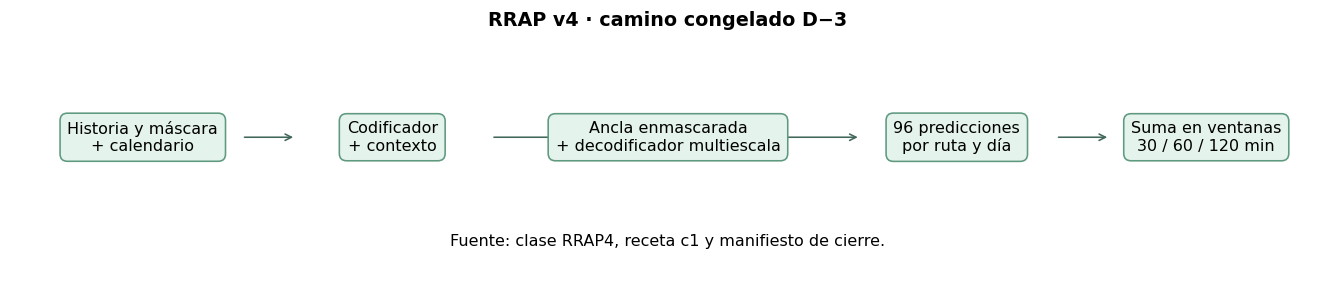

In [3]:
fig, ax = plt.subplots(figsize=(11.5, 2.4), layout="constrained")
ax.set_axis_off()
pasos = ["Historia y máscara\n+ calendario", "Codificador\n+ contexto", "Ancla enmascarada\n+ decodificador multiescala",
         "96 predicciones\npor ruta y día", "Suma en ventanas\n30 / 60 / 120 min"]
pos = [.10, .29, .50, .72, .91]
for x, texto in zip(pos, pasos):
    ax.text(x, .58, texto, ha="center", va="center", transform=ax.transAxes,
            bbox=dict(boxstyle="round,pad=.46", facecolor="#e4f3eb", edgecolor="#5e9980"))
for a, b in zip(pos, pos[1:]):
    ax.annotate("", (b-.073, .58), (a+.075, .58), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="->", color="#42685b"),
                zorder=0)
ax.set_title("RRAP v4 · camino congelado D−3")
ax.text(.5, .13, "Fuente: clase RRAP4, receta c1 y manifiesto de cierre.", ha="center", transform=ax.transAxes)
plt.show()

## 6. Modelo LightGBM L3

El boosting ajusta árboles sucesivos en la escala del enlace. En Poisson, una interpretación de la predicción es $widehat y=exp(F(x))$, con $F(x)$ construido por el conjunto aditivo de árboles. En SOBUSA cada fila describe directamente una ventana. La matriz incorpora ruta, calendario, horizonte, perfiles, historia, oferta y señales agregadas permitidas. La receta fe31 fija el orden de columnas y los códigos categóricos para ajuste e inferencia.

| Ajuste | Configuración congelada |
|---|---|
| Objetivo y criterio de parada | Poisson |
| Número máximo de hojas | 127 |
| Tasa de aprendizaje | 0,03 |
| Observaciones mínimas por hoja | 40 |
| Regularización L2 | 1,0 |
| Bins y muestreo | 255 bins. Fracciones de variables y filas de 1,0. |
| Presupuesto y exportación | 2.000 iteraciones por semilla. Se elige el mínimo de la curva Poisson de parada y se exporta ese prefijo. |

La configuración L3 ya estaba decantada por la etapa de desarrollo. En el cierre se escogió el número de árboles por semilla, sin una nueva búsqueda de configuraciones. No se presenta un ranking de variables L3 como resultado validado. Las explicaciones del GBM empresarial corresponden a otro estimador. [Ke et al., LightGBM](https://papers.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)

## 7. Ensamble SOBUSA v1.0

La mezcla fusiona las predicciones por clave compatible:

$$
widehat y^{,mathrm{v1}}_{r,t,H}
;=;0.5left(rac1{5}sum_{s=0}^{4}widehat y^{,mathrm{RRAP},s}_{r,t,H}
ight)
+0.5left(rac1{5}sum_{s=0}^{4}widehat y^{,mathrm{L3},s}_{r,t,H}
ight).
$$

| Semilla | Época RRAP | Árboles L3 |
|---:|---:|---:|
| 0 | 19 | 383 |
| 1 | 22 | 399 |
| 2 | 26 | 415 |
| 3 | 25 | 419 |
| 4 | 19 | 410 |

*Fuente de la tabla: manifiesto `sobusa-v1.0-p25-d3-r01`.* Se congelaron cinco estados PyTorch, cinco boosters de texto, horario y metadatos. El cargador compara SHA-256 antes de interpretar pesos, carga estados RRAP en CPU con `weights_only=True` y verifica el número de árboles de cada booster. El mero promedio de errores de las semillas no produce el error del promedio de predicciones.

## 8. Métricas de evaluación

Sea $I$ el conjunto de ventanas con etiqueta y predicción verificables. Para el MASE, $a_{rh}$ es la media de diferencias absolutas de pasajeros entre pares originales y desplazados siete días con igual ruta, horizonte y hora. Los pares provienen de la partición histórica de entrenamiento del archivo de referencia, que abarca el soporte designado de entrenamiento y parada previo a p25. Se conservan sus escalas positivas auditadas. Es una escala de evaluación distinta de la normalización interna de RRAP.

$$
egin{aligned}
operatorname{MASE}&=rac{1}{|I|}sum_{iin I}rac{|e_i|}{a_{r_i h_i}},&
operatorname{MAE}&=rac{1}{|I|}sum_{iin I}|e_i|,\
operatorname{RMSE}&=sqrt{rac{1}{|I|}sum_{iin I}e_i^2},&
operatorname{WAPE}&=rac{sum_{iin I}|e_i|}{sum_{iin I}|y_i|},\
operatorname{sMAPE}&=rac{1}{|I|}sum_{iin I}rac{2|e_i|}{|y_i|+|widehat y_i|},&
e_i&=widehat y_i-y_i .
end{aligned}
$$

El MASE es adimensional y trata cada ventana evaluable por igual. El MAE y el RMSE se expresan en pasajeros por ventana. El RMSE penaliza más los errores grandes. WAPE y sMAPE se expresan como porcentajes al multiplicar por 100. WAPE requiere volumen observado positivo y da mayor peso a grupos de volumen alto. En sMAPE dos ceros aportan cero y un solo cero aporta 200 %. El sesgo firmado resume sobrepredicción y subpredicción y puede ocultar compensaciones. [Hyndman y Koehler (2006)](https://doi.org/10.1016/j.ijforecast.2006.03.001)

## 9. Resultados experimentales

La tabla pública usa los tres valores globales autorizados, redondeados a seis decimales y cotejados con `cierre_v1/metricas_v1.csv`. La gráfica los representa en la misma escala. Las tablas detalladas y los perfiles de errores se ejecutan con la evidencia privada.

,MASE
RRAP v4,0.587081
LightGBM L3,0.593973
SOBUSA 50/50,0.580325


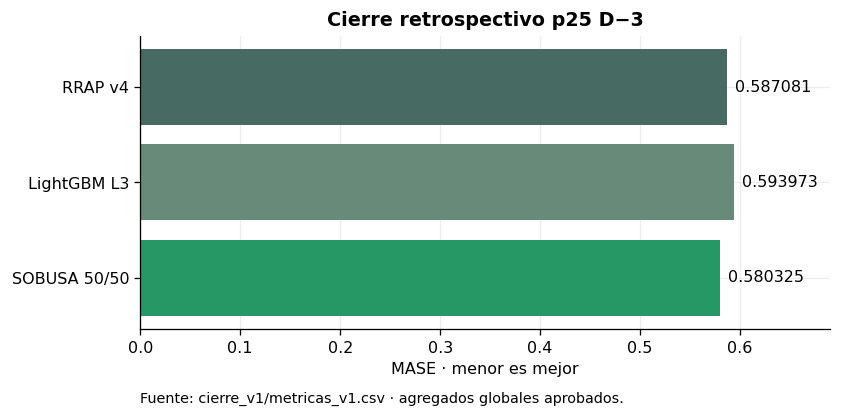

In [4]:
modelos = {"rrap": "RRAP v4", "lgbm": "LightGBM L3", "fijo": "SOBUSA 50/50"}
resultado_publico = pd.Series([.587081, .593973, .580325], index=list(modelos), name="MASE")
if evidencia:
    cierre_metricas = pd.read_csv(CIERRE / "metricas_v1.csv")
    global_cierre = cierre_metricas.loc[cierre_metricas.nivel.eq("global")].set_index("modelo")
    np.testing.assert_allclose(global_cierre.loc[list(modelos), "mase"], resultado_publico, rtol=0, atol=5e-7)
resumen = resultado_publico.rename(index=modelos).to_frame()
display(resumen.style.format("{:.6f}"))

fig, ax = plt.subplots(figsize=(7.2, 3.5), layout="constrained")
barras = ax.barh(resumen.index, resumen.MASE, color=PALETA)
ax.invert_yaxis()
ax.bar_label(barras, fmt="%.6f", padding=5)
ax.set(xlim=(0, .69), xlabel="MASE · menor es mejor", title="Cierre retrospectivo p25 D−3")
ax.text(0, -.25, "Fuente: cierre_v1/metricas_v1.csv · agregados globales aprobados.",
        transform=ax.transAxes, fontsize=9)
plt.show()

El 50/50 reduce el MASE en **0,006755** respecto a RRAP, alrededor de **1,15 %**, y en **0,013648** respecto a L3, alrededor de **2,30 %**. Se trata de diferencias descriptivas sobre ventanas coincidentes. El estudio archivó comparaciones pareadas con bloques móviles de siete días y 2.000 réplicas. El contraste con RRAP no permite concluir una ventaja estadística en ese protocolo. La reutilización de p25 limita cualquier lectura confirmatoria general.

In [5]:
def metricas(v, nombre):
    y, q = v.y_pasajeros.to_numpy(), v[nombre].to_numpy()
    error = q-y
    abs_error = abs(error)
    den = abs(y)+abs(q)
    volumen = abs(y).sum()
    return dict(n=len(y), MASE=np.mean(abs_error/v.escala), MAE=abs_error.mean(),
                RMSE=np.sqrt(np.mean(error**2)), WAPE=100*abs_error.sum()/volumen if volumen else np.nan,
                sMAPE=100*np.divide(2*abs_error, den, out=np.zeros_like(error, dtype=float), where=den>0).mean(),
                sesgo=error.mean())

referencia = None
if evidencia:
    referencia = parquet_archivado("predicciones.parquet")
    claves = ["id_ruta", "origen", "horizonte_min"]
    semillas = [f"{m}_s{s}" for m in ("rrap", "lgbm") for s in range(5)]
    miembros = [*semillas, *modelos]
    pred_congeladas = pd.read_parquet(CIERRE / "predicciones_v1.parquet", columns=[*claves, *miembros])
    d = referencia.drop(columns=miembros).merge(pred_congeladas, how="left", on=claves, validate="one_to_one")
    assert len(d) == len(referencia) and d.escala.gt(0).all()
    for m in miembros:
        tolerancia = 1e-8 if m.startswith("lgbm") else 1e-4
        np.testing.assert_allclose(d[m], referencia[m], rtol=1e-6, atol=tolerancia, equal_nan=False)
    np.testing.assert_allclose(d.fijo, (d.rrap+d.lgbm)/2, rtol=1e-6, atol=1e-4)
    tabla = pd.DataFrame({m: metricas(d, m) for m in miembros}).T
    np.testing.assert_allclose(tabla.loc[list(modelos), "MASE"], resultado_publico, atol=5e-7, rtol=0)
    display(tabla.round(6))
    desgloses = []
    for campo in ("id_ruta", "horizonte_min"):
        for llave, filas in d.groupby(campo):
            for m, etiqueta in modelos.items():
                desgloses.append({"Corte": campo, "Grupo": llave, "Modelo": etiqueta, **metricas(filas, m)})
    display(pd.DataFrame(desgloses).round(4))
    print("Fuente: predicciones v1 del cierre alineadas con la referencia cronológica p25 verificada.")
else:
    print("Resultados por semilla, ruta y horizonte reservados a la evidencia privada.")

Resultados por semilla, ruta y horizonte reservados a la evidencia privada.


In [6]:
if referencia is not None:
    d = d.assign(error=d.fijo-d.y_pasajeros,
                 error_escalado=(d.fijo-d.y_pasajeros).abs()/d.escala, hora=d.origen.dt.hour)
    caso = d.loc[d.dia.eq(FECHA_DEMO) & d.id_ruta.eq(2) & d.horizonte_min.eq(60)].sort_values("origen")
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), layout="constrained")
    d.groupby("hora").error_escalado.mean().plot(ax=ax[0], color=PALETA[2])
    ax[0].set(title="Error por hora", xlabel="Hora de origen (Bogotá)", ylabel="MASE por ventana")
    ax[1].hist(d.error, bins=60, color=PALETA[2])
    ax[1].set(title="Distribución de residuos", xlabel="Pronóstico − observado (pasajeros)", ylabel="Ventanas")
    for col, color in (("y_pasajeros", PALETA[0]), ("fijo", PALETA[2])):
        ax[2].plot(caso.origen.dt.hour + caso.origen.dt.minute/60, caso[col], label=col, color=color)
    ax[2].legend(frameon=False)
    ax[2].set(title="Fecha fija · ruta 2 · 60 min", xlabel="Hora local", ylabel="Pasajeros por ventana")
    fig.suptitle("Fuente: evaluación privada p25 · pronósticos congelados")
    plt.show()
    display(d.groupby(["id_ruta", "horizonte_min"]).error_escalado.agg(
        ventanas="size", mediana="median", p95=lambda s: s.quantile(.95)).round(3))
else:
    print("Residuos y comparación con observados reservados a la evidencia privada.")

Residuos y comparación con observados reservados a la evidencia privada.


El desglose local separa errores por ruta, ventana y hora. La mediana y el percentil 95 de error escalado describen los casos difíciles sin seleccionar una fecha favorable. El ejemplo de trazado usa la fecha ya fijada para la demostración histórica de la API. Las ventanas de una misma jornada se solapan. Por eso la visualización de muchos puntos no equivale a muchas observaciones independientes.

## 10. Inferencia reproducible

El código llama a `sobusa_v1_runtime.interfaz.predecir`, el mismo punto de entrada que usan FastAPI y la CLI. Configure `SOBUSA_RUNTIME_DIR` con la raíz de la distribución privada si el notebook se abre fuera de ella. `SOBUSA_ARTEFACTOS_DIR` indica el directorio de los diez modelos, el horario y el manifiesto. Use `SOBUSA_MODO_NOTEBOOK=retrospectivo` con `SOBUSA_HISTORICO_DIR` para repetir el 1 de mayo de 2025. Con los pesos y el runtime disponibles, el modo predeterminado genera viajes ficticios antes del corte y usa los pesos reales. Cuando esos activos faltan, la celda informa la dependencia.

In [7]:
requeridas = ["pandas", "numpy", "matplotlib", "torch", "lightgbm", "pyarrow", "sklearn"]
faltan = [m for m in requeridas if importlib.util.find_spec(m) is None]
ubicacion = os.getenv("SOBUSA_RUNTIME_DIR")
raiz = Path(ubicacion) if ubicacion else next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p/"sobusa_v1_runtime").is_dir()), Path.cwd())
archivo_artefactos = Path(os.getenv("SOBUSA_ARTEFACTOS_DIR", f"artefactos/{VERSION}"))
if not archivo_artefactos.is_absolute():
    archivo_artefactos = raiz / archivo_artefactos
modelos_esperados = [f"rrap_s{i}.pt" for i in range(5)] + [f"lgbm_s{i}.txt" for i in range(5)]
presentes = all((archivo_artefactos / f).is_file()
                for f in [*modelos_esperados, "manifiesto.json", "horario.csv"])
runtime = (raiz/"sobusa_v1_runtime/interfaz.py").is_file()
if faltan:
    print("Dependencias de inferencia ausentes:", ", ".join(faltan))
prediccion = None
if runtime and presentes and not faltan:
    manifiesto_path = archivo_artefactos / "manifiesto.json"
    if huella(manifiesto_path) != SHA_MANIFIESTO:
        raise ValueError("El manifiesto no coincide con la versión aprobada.")
    inventario_modelo = json.loads(manifiesto_path.read_text(encoding="utf-8"))
    assert sorted(a["archivo"] for a in inventario_modelo["artefactos"]) == sorted(modelos_esperados)
    for a in inventario_modelo["artefactos"]:
        if huella(archivo_artefactos / a["archivo"]) != a["sha256"]:
            raise ValueError("Artefacto alterado: " + a["archivo"])
    sys.path.insert(0, str(raiz))
    from sobusa_v1_runtime.interfaz import predecir

    modo = os.getenv("SOBUSA_MODO_NOTEBOOK", "sintetico")
    if modo == "retrospectivo" and not os.getenv("SOBUSA_HISTORICO_DIR"):
        print("Configure SOBUSA_HISTORICO_DIR para reproducir el histórico del ejemplo.")
    else:
        prediccion = predecir(FECHA_DEMO, RUTAS, HORIZONTES, modo=modo)
        meta = prediccion["metadata"]
        assert meta["version"] == VERSION and meta["modo"] == modo
        f = pd.DataFrame(prediccion["filas"])
        assert set(zip(f.idruta, f.horizonte_min)) == {(r,h) for r in RUTAS for h in HORIZONTES}
        np.testing.assert_allclose(f.demanda_pred, (f.demanda_rrap_v4+f.demanda_lightgbm_l3)/2,
                                   rtol=1e-6, atol=1e-4)
        if modo == "retrospectivo":
            assert len(meta["paridad"]) == 13 and not any(x["fuera_tolerancia"] for x in meta["paridad"].values())
        print(f"Inferencia {modo}: {len(f)} filas, diez artefactos verificados.")
else:
    print("Para generar predicciones, instale el worker y suministre el runtime y los diez pesos congelados.")

Para generar predicciones, instale el worker y suministre el runtime y los diez pesos congelados.


In [8]:
if prediccion is not None:
    campos = {"demanda_rrap_v4": "RRAP v4", "demanda_lightgbm_l3": "LightGBM L3", "demanda_pred": "SOBUSA 50/50"}
    vista = f.loc[f.idruta.eq(2) & f.horizonte_min.eq(60)].copy()
    x = pd.to_datetime(vista.franja_inicio)
    fig, ax = plt.subplots(figsize=(9, 3.7), layout="constrained")
    for (col, etiqueta), color in zip(campos.items(), PALETA):
        ax.plot(x.dt.hour+x.dt.minute/60, vista[col], label=etiqueta, color=color)
    ax.set(title=f"Inferencia {meta['modo']} · ruta 2 · 60 min",
           xlabel="Hora de salida programada (Bogotá)", ylabel="Pasajeros por ventana")
    ax.legend(frameon=False)
    plt.show()
else:
    print("El gráfico de inferencia requiere un resultado válido del motor común.")

El gráfico de inferencia requiere un resultado válido del motor común.


**Ejemplo Python.** El paso anterior puede invocarse como `predecir("2025-05-01", [2,16,21], [30,60,120], modo="sintetico")`, o mediante `python -m sobusa_v1_runtime --fecha 2025-05-01 --modo sintetico` desde la raíz del runtime. El ejemplo FastAPI usa el mismo modelo explícito y consulta puntos a 60 minutos. Solo se activa si se configura un servicio local y un token efímero de operador, según la [guía de inferencia](../../README_INFERENCIA.md).

In [9]:
from urllib.parse import urlsplit
from urllib.request import Request, urlopen

url_api = os.getenv("SOBUSA_NOTEBOOK_API_URL")
token_api = os.getenv("SOBUSA_OPERADOR_TOKEN")
solicitud = dict(modelo="sobusa_v1", version=VERSION, fecha=FECHA_DEMO, rutas=RUTAS, horizontes=HORIZONTES)
if url_api and token_api:
    url = urlsplit(url_api)
    if url.scheme != "http" or url.hostname != "127.0.0.1" or url.username or url.password:
        raise ValueError("El ejemplo API solo acepta un servicio HTTP local en 127.0.0.1.")
    base = url_api.rstrip("/") + "/api/v1"
    cabeceras = {"Authorization": "Bearer " + token_api, "Content-Type": "application/json"}
    with urlopen(Request(base+"/candidate-runs", data=json.dumps(solicitud).encode(), headers=cabeceras), timeout=90) as r:
        corrida = json.load(r)
    with urlopen(Request(base+f"/candidate-runs/{corrida['run_id']}/predictions?horizonte_min=60&tamano=500",
                         headers=cabeceras), timeout=15) as r:
        pagina = json.load(r)
    assert corrida["metadata"]["version"] == VERSION
    assert all(row["horizonte_min"]==60 for row in pagina["datos"])
    if prediccion is not None:
        assert corrida["metadata"]["snapshot"] == meta["snapshot"]
        columnas = ["idruta", "franja_inicio", *campos]
        api = pd.DataFrame(pagina["datos"])[columnas].sort_values(columnas[:2]).reset_index(drop=True)
        py = f.loc[f.horizonte_min.eq(60), columnas].sort_values(columnas[:2]).reset_index(drop=True)
        pd.testing.assert_frame_equal(api, py, check_dtype=False, atol=1e-8, rtol=1e-6)
    print("Consulta y paginación de FastAPI comprobadas para el horizonte de 60 minutos.")
else:
    print("Ejemplo API opcional: configure SOBUSA_NOTEBOOK_API_URL y un token de operador local.")

Ejemplo API opcional: configure SOBUSA_NOTEBOOK_API_URL y un token de operador local.


## 11. Integración con SOBUSA

El backend conserva 15 rutas empresariales. `gbm_fe31` usa la implementación de boosting de scikit-learn y el registro empresarial. El candidato requiere `SOBUSA_CANDIDATO_LOCAL=1` y la selección explícita `sobusa_v1` con su versión. El worker separado evita imponer al backend las versiones de bibliotecas del candidato.

La API registra corridas candidatas en memoria y devuelve pronósticos por familia, mezcla y metadatos de versión y cobertura. Los endpoints candidatos no persisten pronósticos en las tablas empresariales. La simulación de despacho se apoya en el pronóstico a 60 minutos y necesita los parámetros de simulación correspondientes. El dashboard actual consume los endpoints empresariales. Incorporar una vista candidata en el dashboard y validar persistencia e intervalos requieren trabajo separado.

## 12. Discusión y limitaciones

RRAP produce primero una curva de 96 franjas y suma en ventanas, mientras L3 pronostica directamente por horizonte. Esa diferencia da margen a errores complementarios y también a incoherencia aditiva. La suma de subventanas se examinó en el diagnóstico retrospectivo y el cierre conservó las salidas por horizonte. La aditividad importa al traducir conteos en recursos discretos. Se recomienda usar el horizonte de la decisión al interpretar la simulación.

La reducción agregada de error no garantiza mejoras por ruta, horizonte o día. Los perfiles privados permiten verificar dónde se concentra el error. El tamaño de la muestra depende de la cobertura de etiquetas y del tipo de día, y las franjas superpuestas exigen inferencia temporal por bloques. Las escalas y el horario se congelaron sin usar las etiquetas de evaluación. Los posibles cambios retrospectivos del snapshot y la selección previa de configuraciones limitan la generalización.

El modelo candidato carece de intervalos calibrados. La cobertura madura insuficiente de varios estratos impidió aprobar la calibración con los datos disponibles. Falta validar fechas nuevas con entradas versionadas y recibidas antes del corte, además de validar con PostgreSQL los flujos de persistencia que lo requieran.

## 13. Conclusiones

La mezcla congelada obtuvo el menor MASE global entre los tres comparadores de p25 D−3. La verificación cubrió los diez modelos por semilla, las medias por familia y el 50/50. Un único motor sirve Python, Jupyter y FastAPI y separa el pronóstico de pasajeros de la simulación puntual de frecuencias. Esta evidencia respalda la reproducción retrospectiva y una demostración sintética con activos autorizados. La puesta en operación depende de la disponibilidad real al corte, la validación prospectiva y la decisión sobre intervalos y persistencia.

## 14. Reproducibilidad y referencias

**Entorno verificado.** Python 3.12.14 AMD64 CPU, NumPy 2.3.5, pandas 3.0.1, LightGBM 4.6.0, PyTorch 2.7.1, PyArrow 20.0.0, scikit-learn 1.6.1, Matplotlib 3.10.3 e ipykernel 6.29.5. La instalación usa el lock separado del worker. Las semillas congeladas son 0 a 4 para cada familia. El backend usa su propio lock.

| Ancla | SHA-256 |
|---|---|
| Manifiesto congelado | `d6db1f83e479730c48371535781461016f02543d327576b7fabd9bbf4c383420` |
| Distribución privada de inferencia Windows AMD64 | `bfe299861679be0422bdba4b838942515a69d46aeac134eb3bb13637236f6b3c` |

El repositorio conserva `app/` (API y servicios), `dashboard/`, `dependencias/`, `ejemplos/` y `eda/`. Los activos autorizados se proporcionan localmente según el [README de inferencia](../../README_INFERENCIA.md). Para las celdas detalladas, `SOBUSA_EVIDENCIA_DIR` apunta al directorio privado que contiene `desarrollo_modelo_original`, con `cierre_v1` y `resultados`. La publicación no incorpora las tablas por fila, los pesos, el código privado ni las salidas detalladas. Este cuaderno no lanza entrenamiento ni selección.

```powershell
& ./dependencias/instalar-local.ps1 -Python python -Ruedas <directorio-autorizado>
& ./.venv-worker/Scripts/python.exe -m ipykernel install --user --name sobusa-v1-worker
& ./.venv-worker/Scripts/python.exe -m sobusa_v1_runtime --fecha 2025-05-01 --modo sintetico
```

**Documentos del estudio.** `AUDITORIA.md` e inventario de viajes (procedencia), `PROTOCOLO.md`, `AUDITORIA_V1.md` y preflight (diseño y madurez), `cierre_v1/INFORME_CIERRE.md`, `metricas_v1.csv` y `TOLERANCIAS.md` (resultados y criterios de paridad), guía y verificación de la distribución privada (integración).

**Referencias bibliográficas.**

- Hyndman, R. J., y Koehler, A. B. (2006). *Another look at measures of forecast accuracy*. International Journal of Forecasting, 22(4), 679–688. [Artículo](https://doi.org/10.1016/j.ijforecast.2006.03.001)
- Ke, G. et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS 30. [Artículo](https://papers.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)
- Challu, C. et al. (2023). *N-HiTS: Neural Hierarchical Interpolation for Time Series Forecasting*. Antecedente para construir representaciones a distintas escalas. [Artículo](https://arxiv.org/abs/2201.12886)
- Wang, X., Hyndman, R. J., Li, F., y Kang, Y. (2023). *Forecast combinations: An over 50-year review*. International Journal of Forecasting. [Artículo](https://doi.org/10.1016/j.ijforecast.2022.11.005)
- Cawley, G. C., y Talbot, N. L. C. (2010). *On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation*. JMLR, 11, 2079–2107. [Artículo](https://www.jmlr.org/papers/v11/cawley10a.html)